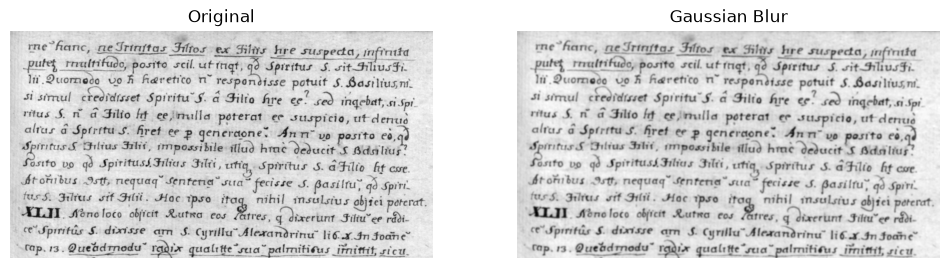

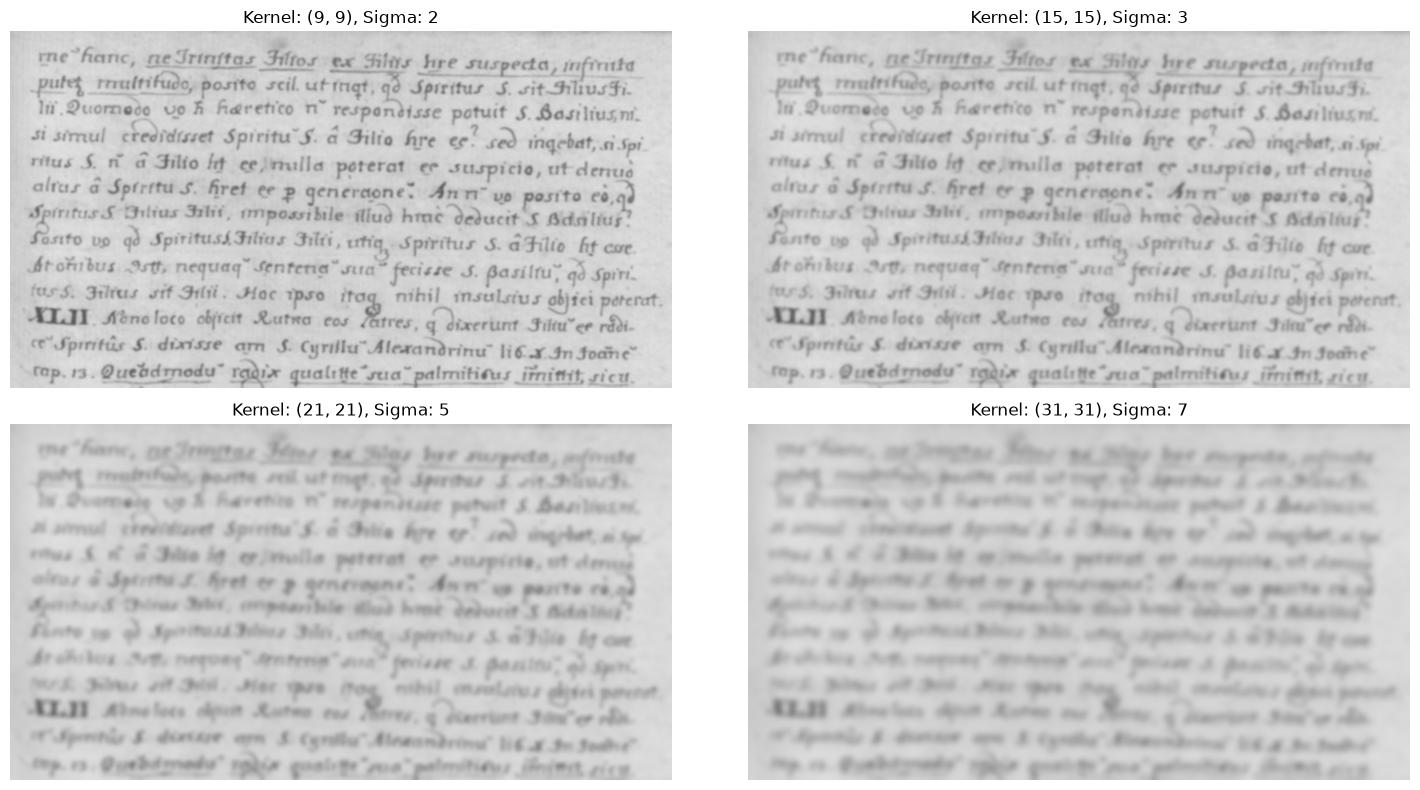

In [2]:
import cv2
import matplotlib.pyplot as plt

# Load original document
original = cv2.imread("Test.jpeg", cv2.IMREAD_GRAYSCALE)

# Apply Gaussian blur
blurred = cv2.GaussianBlur(original, (9, 9), 2)

# Display both
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.show()

blur_settings = [
    ((9, 9), 2),
    ((15, 15), 3),
    ((21, 21), 5),
    ((31, 31), 7)
]

plt.figure(figsize=(15, 8))

for i, (kernel, sigma) in enumerate(blur_settings):
    blurred = cv2.GaussianBlur(original, kernel, sigma)

    plt.subplot(2, 2, i + 1)
    plt.imshow(blurred, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Kernel: {kernel}, Sigma: {sigma}")
    plt.axis("off")

plt.tight_layout()
plt.show()

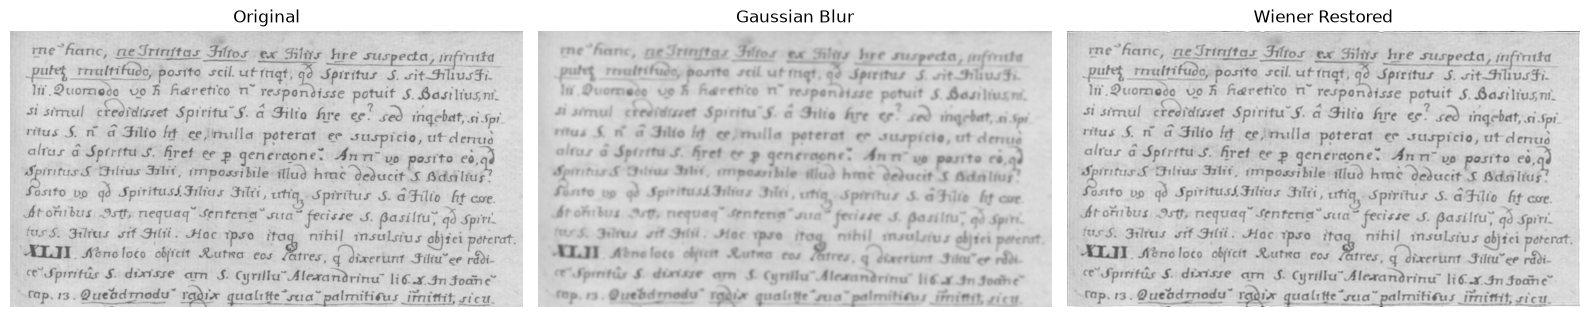

In [3]:
import numpy as np
# Load original
original = cv2.imread("Test.jpeg", cv2.IMREAD_GRAYSCALE)

# Create a Gaussian kernel
kernel_size = 15
sigma = 3

g = cv2.getGaussianKernel(kernel_size, sigma)
kernel = g @ g.T

# Blur the image using that kernel
blurred = cv2.filter2D(original, -1, kernel)

# Wiener deconvolution
def wiener_deblur(image, kernel, K=0.001):
    image = image.astype(np.float32) / 255.0

    # Pad and align kernel with the image
    h, w = image.shape
    kh, kw = kernel.shape

    psf = np.zeros((h, w), dtype=np.float32)
    psf[:kh, :kw] = kernel
    psf = np.roll(psf, (-kh // 2 + 1, -kw // 2 + 1), axis=(0, 1))

    # Fourier transforms
    G = np.fft.fft2(image)
    H = np.fft.fft2(psf)

    # Wiener filter
    F = (np.conj(H) / (np.abs(H)**2 + K)) * G

    # Convert back to spatial domain
    restored = np.real(np.fft.ifft2(F))

    return np.clip(restored * 255, 0, 255).astype(np.uint8)

restored = wiener_deblur(blurred, kernel)

# Compare
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, img, title in zip(
    axes,
    [original, blurred, restored],
    ["Original", "Gaussian Blur", "Wiener Restored"]
):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
from skimage.metrics import peak_signal_noise_ratio

# Compare blurred image against original
psnr_blurred = peak_signal_noise_ratio(original, blurred)


# Compare restored image against original
psnr_restored = peak_signal_noise_ratio(original, restored)


print("Gaussian Blurred:")
print(f"PSNR: {psnr_blurred:.2f} dB")

print("\nWiener Restored:")
print(f"PSNR: {psnr_restored:.2f} dB")

Gaussian Blurred:
PSNR: 26.01 dB

Wiener Restored:
PSNR: 31.52 dB


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr

# Different K values to experiment with
k_values = [0.00001, 0.0001, 0.001, 0.01, 0.1]

psnr_results = []
restored_images = []

for k in k_values:

    # Restore using current K value
    result = wiener_deblur(blurred, kernel, K=k)

    # Compare restored image to original
    score = psnr(original, result, data_range=255)

    psnr_results.append(score)
    restored_images.append(result)

    print(f"K = {k}: PSNR = {score:.2f} dB")

# Find the best K value
best_index = np.argmax(psnr_results)
best_k = k_values[best_index]

print(f"\nBest K: {best_k}")
print(f"Best PSNR: {psnr_results[best_index]:.2f} dB")

K = 1e-05: PSNR = 18.26 dB
K = 0.0001: PSNR = 25.31 dB
K = 0.001: PSNR = 31.52 dB
K = 0.01: PSNR = 30.30 dB
K = 0.1: PSNR = 21.45 dB

Best K: 0.001
Best PSNR: 31.52 dB


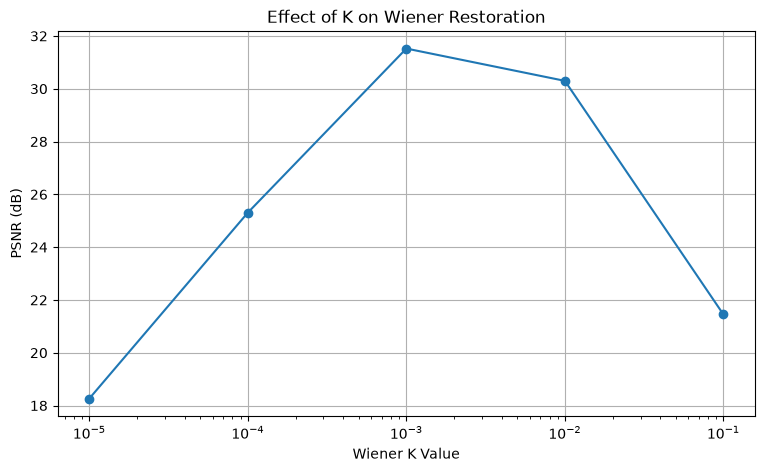

In [6]:
plt.figure(figsize=(9, 5))

plt.plot(k_values, psnr_results, marker="o")

plt.xscale("log")
plt.xlabel("Wiener K Value")
plt.ylabel("PSNR (dB)")
plt.title("Effect of K on Wiener Restoration")
plt.grid(True)

plt.show()

Best K: 0.001887
Best PSNR: 31.83 dB


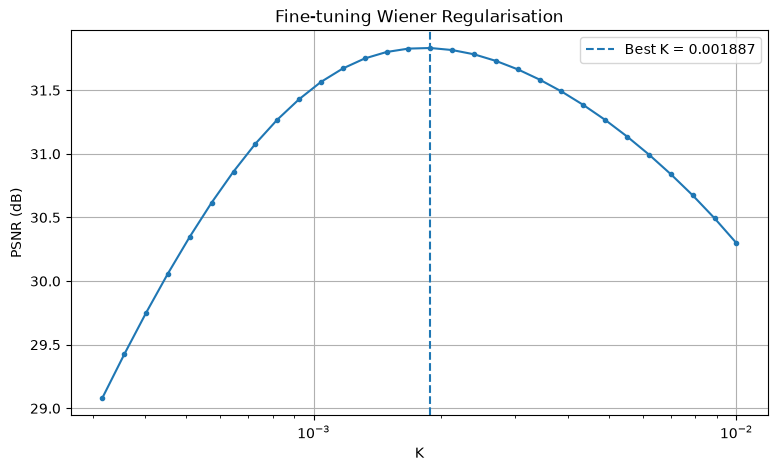

In [7]:
k_values = np.logspace(-3.5, -2, 30)

psnr_results = []

for k in k_values:
    result = wiener_deblur(blurred, kernel, K=k)
    score = psnr(original, result, data_range=255)
    psnr_results.append(score)

best_index = np.argmax(psnr_results)
best_k = k_values[best_index]

print(f"Best K: {best_k:.6f}")
print(f"Best PSNR: {psnr_results[best_index]:.2f} dB")

plt.figure(figsize=(9, 5))
plt.plot(k_values, psnr_results, marker=".")
plt.axvline(best_k, linestyle="--", label=f"Best K = {best_k:.6f}")
plt.xscale("log")
plt.xlabel("K")
plt.ylabel("PSNR (dB)")
plt.title("Fine-tuning Wiener Regularisation")
plt.legend()
plt.grid(True)
plt.show()

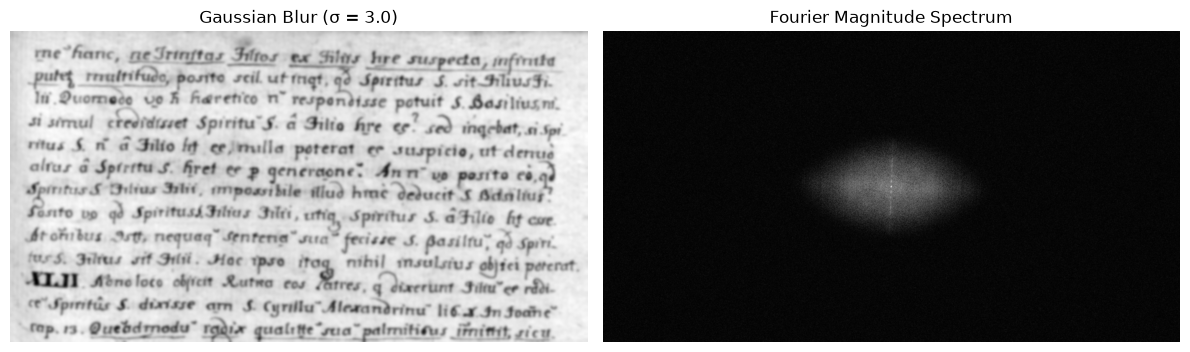

In [29]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Known sigma for testing only
test_sigma = 3.0

# Apply Gaussian blur
blurred = cv2.GaussianBlur(
    original,
    (0, 0),
    sigmaX=test_sigma
)

# Fourier transform with a Hann window
img = blurred.astype(np.float32) / 255.0

window_y = np.hanning(img.shape[0])
window_x = np.hanning(img.shape[1])
window = np.outer(window_y, window_x)

fft = np.fft.fftshift(np.fft.fft2(img * window))

# Display Fourier spectrum
spectrum = np.log1p(np.abs(fft))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(blurred, cmap="gray")
axes[0].set_title(f"Gaussian Blur (σ = {test_sigma})")

axes[1].imshow(spectrum, cmap="gray")
axes[1].set_title("Fourier Magnitude Spectrum")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

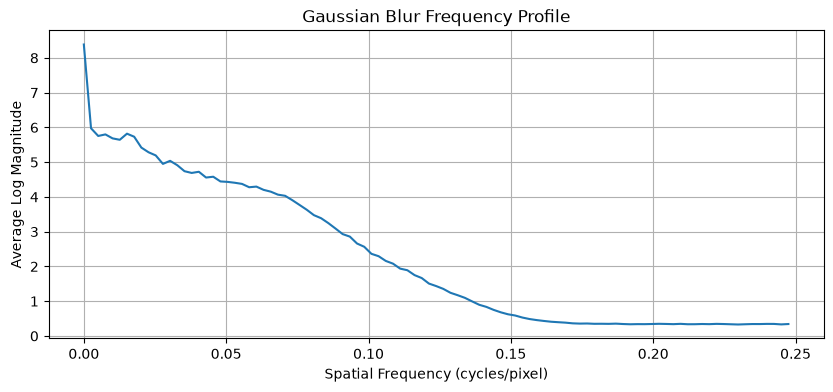

In [30]:
# Calculate distance from the centre of the spectrum
h, w = spectrum.shape
cy, cx = h // 2, w // 2

y, x = np.indices((h, w))

# Normalised frequency distance
radius = np.sqrt(
    ((x - cx) / w)**2 +
    ((y - cy) / h)**2
)

# Divide frequencies into groups
bins = np.linspace(0, 0.25, 100)

radial_profile = []

for i in range(len(bins) - 1):
    mask = (radius >= bins[i]) & (radius < bins[i + 1])

    radial_profile.append(
        np.mean(spectrum[mask]) if np.any(mask) else 0
    )

# Plot average magnitude at each frequency
plt.figure(figsize=(10, 4))

plt.plot(bins[:-1], radial_profile)

plt.xlabel("Spatial Frequency (cycles/pixel)")
plt.ylabel("Average Log Magnitude")
plt.title("Gaussian Blur Frequency Profile")

plt.grid(True)
plt.show()

Actual sigma: 3.0
Estimated sigma: 2.04


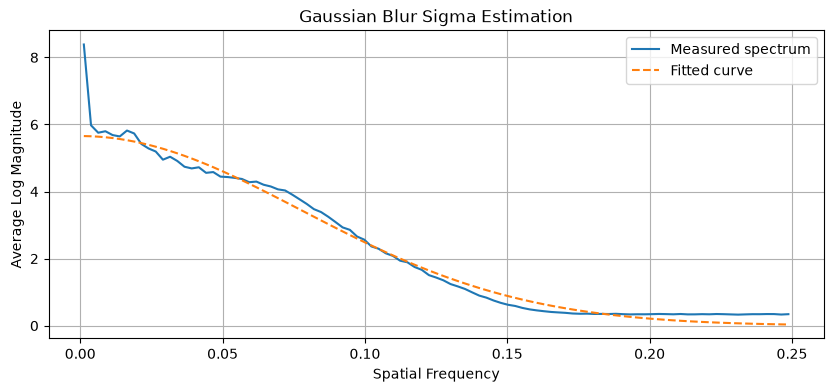

In [31]:
from scipy.optimize import curve_fit

# Gaussian decay model
def gaussian_decay(f, A, b, C):
    return A * np.exp(-b * f**2) + C

# Convert our profile into arrays
freq = (bins[:-1] + bins[1:]) / 2
values = np.array(radial_profile)

# Ignore the very centre and the flat outer region
mask = (freq > 0.01) & (freq < 0.15)

# Fit the model to our measured spectrum
params, _ = curve_fit(
    gaussian_decay,
    freq[mask],
    values[mask],
    p0=[6, 100, 0],
    bounds=([0, 0, 0], [np.inf, np.inf, np.inf]),
    maxfev=10000
)

A, b, C = params

estimated_sigma = np.sqrt(b / (2 * np.pi**2))

print(f"Actual sigma: {test_sigma}")
print(f"Estimated sigma: {estimated_sigma:.2f}")

# Compare measured and fitted curves
plt.figure(figsize=(10, 4))

plt.plot(freq, values, label="Measured spectrum")
plt.plot(
    freq,
    gaussian_decay(freq, *params),
    "--",
    label="Fitted curve"
)

plt.xlabel("Spatial Frequency")
plt.ylabel("Average Log Magnitude")
plt.title("Gaussian Blur Sigma Estimation")
plt.legend()
plt.grid(True)
plt.show()

In [32]:
def measure_edge_sharpness(image):
    # Convert to floating point
    img = image.astype(np.float32)

    # Calculate horizontal and vertical gradients
    gx = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)

    # Calculate gradient magnitude
    magnitude = cv2.magnitude(gx, gy)

    # Focus on stronger edges
    threshold = np.percentile(magnitude, 90)
    strong_edges = magnitude[magnitude > threshold]

    return np.mean(strong_edges)


sharpness = measure_edge_sharpness(blurred)

print(f"Edge sharpness: {sharpness:.2f}")

Edge sharpness: 62.93


Sigma: 1, Sharpness: 160.79
Sigma: 2, Sharpness: 100.09
Sigma: 3, Sharpness: 62.93
Sigma: 4, Sharpness: 42.82
Sigma: 5, Sharpness: 31.73


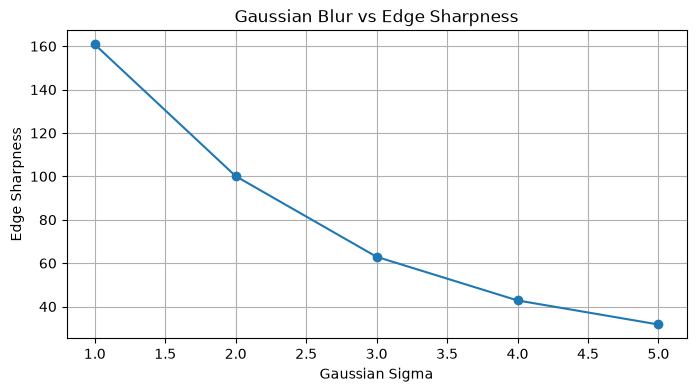

In [34]:
sigmas = [1, 2, 3, 4, 5]
sharpness_scores = []

for sigma in sigmas:
    test_blur = cv2.GaussianBlur(
        original, (0, 0), sigmaX=sigma
    )

    score = measure_edge_sharpness(test_blur)
    sharpness_scores.append(score)

    print(f"Sigma: {sigma}, Sharpness: {score:.2f}")

plt.figure(figsize=(8, 4))
plt.plot(sigmas, sharpness_scores, marker="o")

plt.xlabel("Gaussian Sigma")
plt.ylabel("Edge Sharpness")
plt.title("Gaussian Blur vs Edge Sharpness")
plt.grid(True)
plt.show()

In [36]:
# Convert calibration measurements to arrays
calibration_sigmas = np.array(sigmas, dtype=float)
calibration_scores = np.array(sharpness_scores)

def estimate_gaussian_sigma(image):
    # Measure the sharpness of the input image
    score = measure_edge_sharpness(image)

    # Convert sharpness back into an estimated sigma
    estimated = np.interp(
        score,
        calibration_scores[::-1],
        calibration_sigmas[::-1]
    )

    return estimated


estimated_sigma = estimate_gaussian_sigma(blurred)

print(f"Actual sigma: {test_sigma}")
print(f"Estimated sigma: {estimated_sigma:.2f}")

Actual sigma: 3.0
Estimated sigma: 3.00


In [37]:
test_sigma = 2.5

blurred = cv2.GaussianBlur(
    original,
    (0, 0),
    sigmaX=test_sigma
)

estimated_sigma = estimate_gaussian_sigma(blurred)

print(f"Actual sigma: {test_sigma}")
print(f"Estimated sigma: {estimated_sigma:.2f}")

Actual sigma: 2.5
Estimated sigma: 2.58


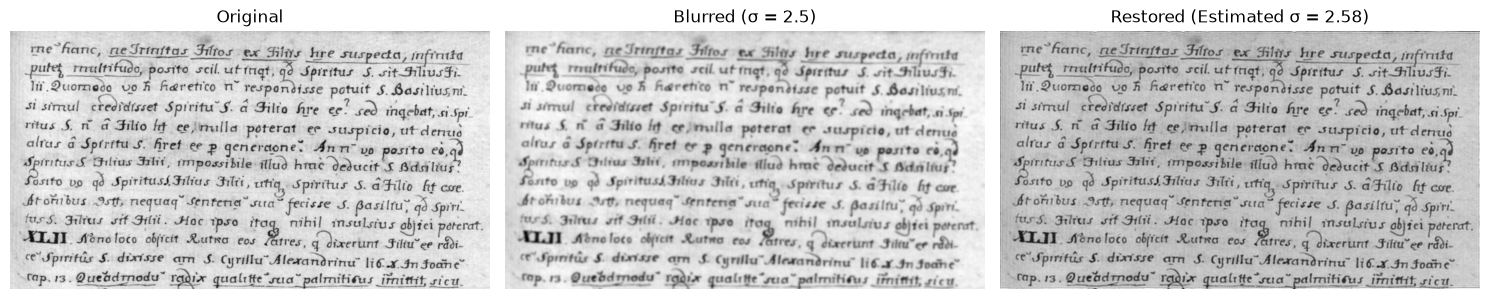

Blurred PSNR: 27.25 dB
Restored PSNR: 34.45 dB


In [38]:
# Generate Gaussian kernel using estimated sigma
kernel_size = int(6 * estimated_sigma + 1)
kernel_size = kernel_size if kernel_size % 2 == 1 else kernel_size + 1

gaussian_1d = cv2.getGaussianKernel(
    kernel_size, estimated_sigma
)

estimated_kernel = gaussian_1d @ gaussian_1d.T

# Restore using estimated Gaussian kernel
restored = wiener_deblur(
    blurred,
    estimated_kernel,
    K=0.001887
)

# Compare results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original, cmap="gray")
axes[0].set_title("Original")

axes[1].imshow(blurred, cmap="gray")
axes[1].set_title(f"Blurred (σ = {test_sigma})")

axes[2].imshow(restored, cmap="gray")
axes[2].set_title(f"Restored (Estimated σ = {estimated_sigma:.2f})")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Blurred PSNR: {cv2.PSNR(original, blurred):.2f} dB")
print(f"Restored PSNR: {cv2.PSNR(original, restored):.2f} dB")

Actual sigma: 2.5
Estimated sigma: 1.98


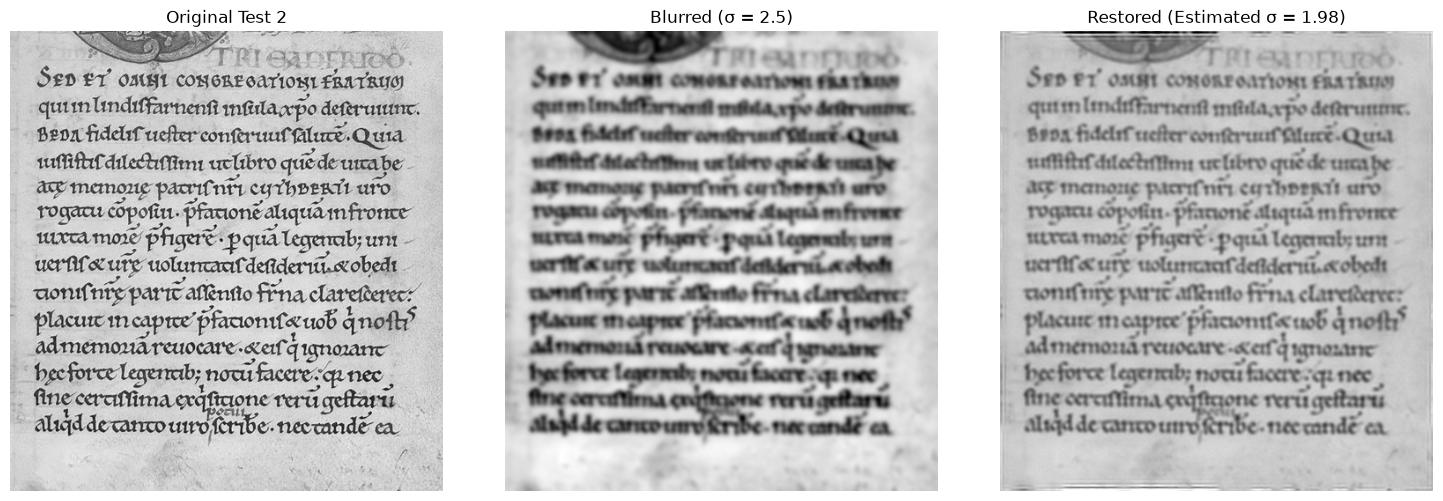

Blurred PSNR: 16.97 dB
Restored PSNR: 18.51 dB


In [42]:
# Test Gaussian estimation on a different manuscript

# Load the new image
test2 = cv2.imread("test2.png", cv2.IMREAD_GRAYSCALE)

if test2 is None:
    raise FileNotFoundError("Could not find test2.jpeg")

# Apply a known Gaussian blur for testing
test_sigma = 2.5

test2_blurred = cv2.GaussianBlur(
    test2, (0, 0), sigmaX=test_sigma
)

# Estimate sigma using our EXISTING calibration
estimated_sigma = estimate_gaussian_sigma(test2_blurred)

print(f"Actual sigma: {test_sigma}")
print(f"Estimated sigma: {estimated_sigma:.2f}")

# Generate Gaussian kernel from estimated sigma
kernel_size = int(6 * estimated_sigma + 1)
if kernel_size % 2 == 0:
    kernel_size += 1

gaussian_1d = cv2.getGaussianKernel(
    kernel_size, estimated_sigma
)

estimated_kernel = gaussian_1d @ gaussian_1d.T

# Restore using Wiener deconvolution
restored = wiener_deblur(
    test2_blurred,
    estimated_kernel,
    K=0.001887
)

# Display comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(test2, cmap="gray")
axes[0].set_title("Original Test 2")

axes[1].imshow(test2_blurred, cmap="gray")
axes[1].set_title(f"Blurred (σ = {test_sigma})")

axes[2].imshow(restored, cmap="gray")
axes[2].set_title(f"Restored (Estimated σ = {estimated_sigma:.2f})")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Compare PSNR
print(f"Blurred PSNR: {cv2.PSNR(test2, test2_blurred):.2f} dB")
print(f"Restored PSNR: {cv2.PSNR(test2, restored):.2f} dB")

In [ ]:
def restore_gaussian_blur(image, sigma=None, K=0.001887):
    # Estimate sigma if not provided
    if sigma is None:
        sigma = estimate_gaussian_sigma(image)

    # Create Gaussian kernel
    kernel_size = int(6 * sigma + 1)

    if kernel_size % 2 == 0:
        kernel_size += 1

    gaussian_1d = cv2.getGaussianKernel(kernel_size, sigma)
    kernel = gaussian_1d @ gaussian_1d.T

    # Restore image
    restored = wiener_deblur(image, kernel, K=K)

    return restored